In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from modules.ground_filter import classify_ground_and_vegetation
from modules.spectral_typing import classify_pioneer_morphology, compute_vari
from modules.terrain_aba import (
    epoch_differences,
    rasters,
    characteristics,
)

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "clips_drone"
OUT_DIR = PROJECT_ROOT / "data" / "output"

clip_files = [
    DATA_DIR / "20230927_72220_72420_451650_451850.laz",  # Autumn 2023
    DATA_DIR / "20240227_72220_72420_451650_451850.laz",  # Winter 2024
    DATA_DIR / "20240501_72220_72420_451650_451850.laz",  # Spring 2024
    DATA_DIR / "20240607_72220_72420_451650_451850.laz",  # Summer 2024
]

In [3]:
print("--- Question A1: Multi-Epoch Metadata & Density ---")
df_a1 = characteristics([str(f) for f in clip_files])
display(df_a1)

--- Question A1: Multi-Epoch Metadata & Density ---


,Epoch,File Name,Total Points,X Bounds (m),Y Bounds (m),Z Range (m),Area (m²),Pulse Density (pts/m²),Attributes
0,20230927,20230927_72220_72420_451650_451850.laz,21604316,"[72220.0, 72420.0]","[451650.0, 451850.0]","[-0.36, 6.74]",40000.0,540.11,"X, Y, Z, intensity, return_number, number_of_r..."
1,20240227,20240227_72220_72420_451650_451850.laz,19270616,"[72220.0, 72420.0]","[451650.0, 451850.0]","[-1.01, 6.67]",40000.0,481.77,"X, Y, Z, intensity, return_number, number_of_r..."
2,20240501,20240501_72220_72420_451650_451850.laz,50552772,"[72220.0, 72420.0]","[451650.0, 451850.0]","[-0.64, 6.69]",40000.0,1263.82,"X, Y, Z, intensity, return_number, number_of_r..."
3,20240607,20240607_72220_72420_451650_451850.laz,50024807,"[72220.0, 72420.0]","[451650.0, 451850.0]","[-0.66, 6.84]",40000.0,1250.62,"X, Y, Z, intensity, return_number, number_of_r..."


In [5]:
print("\n--- Question A4: Ground Filtering Execution ---")
# Process the Spring 2024 dataset
spring_file = str(clip_files[2])
out_laz = str(OUT_DIR / "spring_classified_diagnostic.laz")

clf_data = classify_ground_and_vegetation(spring_file, output_laz_path=out_laz)
print(f"Total Points: {clf_data['total_points']:,}")
print(f"Ground Points (ASPRS 2): {len(clf_data['ground_idx']):,}")
print(f"Vegetation Points (ASPRS 4): {len(clf_data['veg_idx']):,}")


--- Question A4: Ground Filtering Execution ---
Total Points: 50,552,772
Ground Points (ASPRS 2): 50,289,350
Vegetation Points (ASPRS 4): 263,422


In [4]:
# --- AUTOMATIC PATCH FINDER FOR A2 ---
# 1. Vegetation coordinates
veg_xyz = clf_data["coords"][clf_data["veg_idx"]]

# 2. Local relative height above minimum in local neighborhoods
# Find a tall clump (Marram candidate: height > 35 cm)
tall_mask = veg_xyz[:, 2] > (np.percentile(veg_xyz[:, 2], 90))
tall_candidate = veg_xyz[tall_mask][0]

# Find a low clump (Sand couch candidate: height < 20 cm)
low_mask = (veg_xyz[:, 2] > np.percentile(veg_xyz[:, 2], 10)) & (
    veg_xyz[:, 2] < np.percentile(veg_xyz[:, 2], 30)
)
low_candidate = veg_xyz[low_mask][0]

# Find a bare sand point (from ground points)
ground_xyz = clf_data["coords"][clf_data["ground_idx"]]
sand_candidate = ground_xyz[len(ground_xyz) // 2]

print("Recommended Patch Coordinates for A2:")
print(f"Patch 1 (Tall Clump): X = {tall_candidate[0]:.2f}, Y = {tall_candidate[1]:.2f}")
print(f"Patch 2 (Low Clump):  X = {low_candidate[0]:.2f}, Y = {low_candidate[1]:.2f}")
print(f"Patch 3 (Bare Sand):  X = {sand_candidate[0]:.2f}, Y = {sand_candidate[1]:.2f}")

NameError: name 'clf_data' is not defined

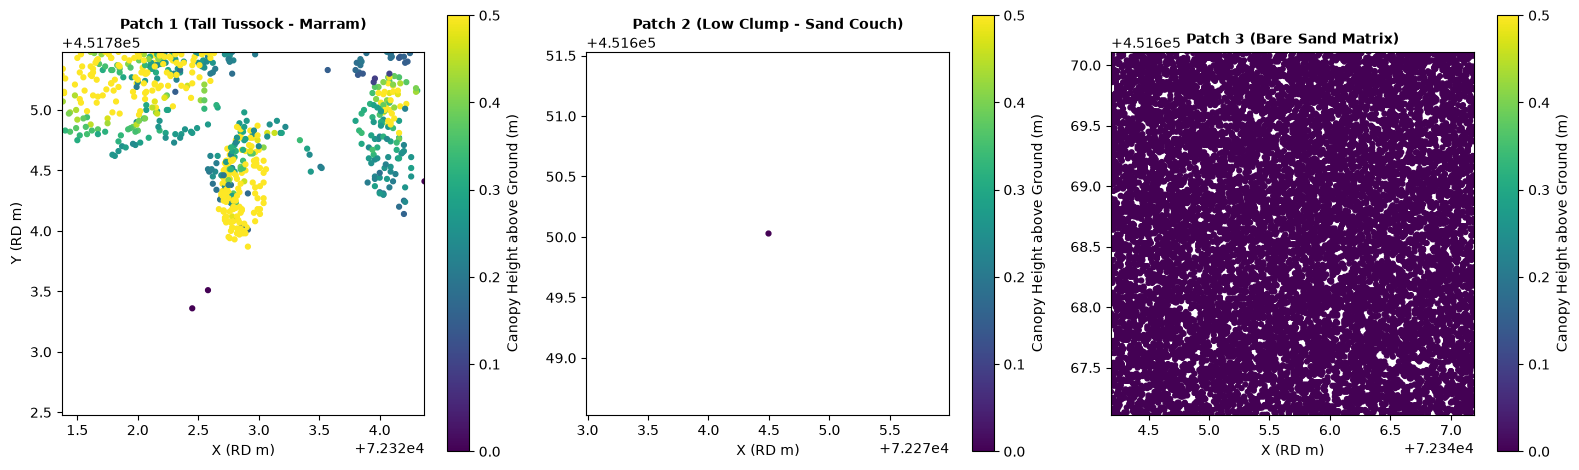

,Occurrence,Center X,Center Y,Points Plotted,Max Canopy Height (m),Mean VARI (Greenness),Interpreted Type
0,Patch 1 (Tall Tussock - Marram),72322.87,451783.98,643,1.27,-0.054,Dry Driftline / Senescent Matter
1,Patch 2 (Low Clump - Sand Couch),72274.49,451650.03,1,0.00,-0.068,Dry Driftline / Senescent Matter
2,Patch 3 (Bare Sand Matrix),72345.69,451668.61,12973,0.00,-0.075,Bare Sand Dune


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from modules.spectral_typing import classify_pioneer_morphology, compute_vari

coords = clf_data["coords"]
las = clf_data["las"]
veg_idx = clf_data["veg_idx"]
ground_idx = clf_data["ground_idx"]

# Compute VARI
vari = compute_vari(las.red, las.green, las.blue)

# Separate coordinates
veg_coords = coords[veg_idx]
veg_vari = vari[veg_idx]

ground_coords = coords[ground_idx]

# Selected patch centers
patches = {
    "Patch 1 (Tall Tussock - Marram)": {
        "x": 72322.87,
        "y": 451783.98,
        "r": 1.5,
        "is_veg": True,
    },
    "Patch 2 (Low Clump - Sand Couch)": {
        "x": 72274.49,
        "y": 451650.03,
        "r": 1.5,
        "is_veg": True,
    },
    "Patch 3 (Bare Sand Matrix)": {
        "x": 72345.69,
        "y": 451668.61,
        "r": 1.5,
        "is_veg": False,
    },
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
summary_a2 = []

for i, (name, b) in enumerate(patches.items()):
    ax = axes[i]

    # Find local ground elevation to subtract the dune slope
    g_mask = (
        (ground_coords[:, 0] >= b["x"] - b["r"])
        & (ground_coords[:, 0] <= b["x"] + b["r"])
        & (ground_coords[:, 1] >= b["y"] - b["r"])
        & (ground_coords[:, 1] <= b["y"] + b["r"])
    )
    local_ground_z = (
        np.median(ground_coords[g_mask, 2])
        if np.any(g_mask)
        else b.get("z", 0.0)
    )

    if b["is_veg"]:
        # Select ONLY vegetation points inside the window
        v_mask = (
            (veg_coords[:, 0] >= b["x"] - b["r"])
            & (veg_coords[:, 0] <= b["x"] + b["r"])
            & (veg_coords[:, 1] >= b["y"] - b["r"])
            & (veg_coords[:, 1] <= b["y"] + b["r"])
        )
        pts = veg_coords[v_mask]
        p_vari = veg_vari[v_mask]
        # True canopy height above the local terrain surface
        p_height = np.maximum(pts[:, 2] - local_ground_z, 0.0)
    else:
        # Bare sand patch (show ground returns)
        pts = ground_coords[g_mask]
        p_vari = vari[ground_idx][g_mask]
        p_height = np.zeros(len(pts))  # Ground has 0 canopy height

    if len(pts) > 0:
        sc = ax.scatter(
            pts[:, 0],
            pts[:, 1],
            c=p_height,
            cmap="viridis",
            s=12,
            vmin=0.0,
            vmax=0.50,
        )
        plt.colorbar(sc, ax=ax, label="Canopy Height above Ground (m)")
        max_h = float(np.max(p_height))
        mean_v = float(np.mean(p_vari))
    else:
        max_h = 0.0
        mean_v = 0.0

    ax.set_title(name, fontsize=10, fontweight="bold")
    ax.set_xlabel("X (RD m)")
    if i == 0:
        ax.set_ylabel("Y (RD m)")
    ax.set_xlim(b["x"] - b["r"], b["x"] + b["r"])
    ax.set_ylim(b["y"] - b["r"], b["y"] + b["r"])
    ax.set_aspect("equal", "box")

    summary_a2.append({
        "Occurrence": name,
        "Center X": b["x"],
        "Center Y": b["y"],
        "Points Plotted": len(pts),
        "Max Canopy Height (m)": round(max_h, 2),
        "Mean VARI (Greenness)": round(mean_v, 3),
        "Interpreted Type": classify_pioneer_morphology(max_h, 0.30, mean_v)
        if b["is_veg"]
        else "Bare Sand Dune",
    })

plt.tight_layout()
plt.show()

display(pd.DataFrame(summary_a2))


--- Question A3: Decoupling Sediment Dynamics from Canopy Growth ---


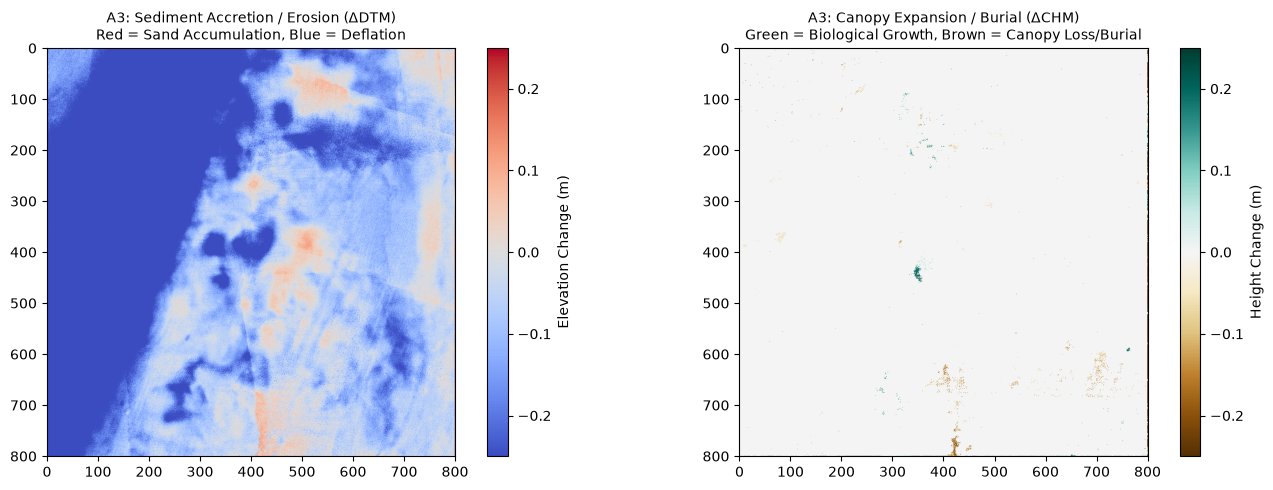

In [7]:
print("\n--- Question A3: Decoupling Sediment Dynamics from Canopy Growth ---")
# Compare Autumn 2023 (clip 0) vs Spring 2024 (clip 2)
clf_t1 = classify_ground_and_vegetation(str(clip_files[0]))
clf_t2 = clf_data  # Already processed Spring 2024

# Lock common spatial subset for 1:1 grid subtraction
common_extent = {
    "x_min": 72260.0,
    "x_max": 72340.0,
    "y_min": 451690.0,
    "y_max": 451770.0,
}

dtm_t1, chm_t1, _, _ = rasters(
    clf_t1["coords"],
    clf_t1["ground_idx"],
    clf_t1["veg_idx"],
    grid_res=0.10,
    bounds_override=common_extent,
)
dtm_t2, chm_t2, _, _ = rasters(
    clf_t2["coords"],
    clf_t2["ground_idx"],
    clf_t2["veg_idx"],
    grid_res=0.10,
    bounds_override=common_extent,
)

delta_dtm, delta_chm = epoch_differences(
    dtm_t1, dtm_t2, chm_t1, chm_t2
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im1 = axes[0].imshow(
    delta_dtm, cmap="coolwarm", vmin=-0.25, vmax=0.25, origin="upper"
)
axes[0].set_title(
    "A3: Sediment Accretion / Erosion (ΔDTM)\nRed = Sand Accumulation, Blue = Deflation",
    fontsize=10,
)
plt.colorbar(im1, ax=axes[0], label="Elevation Change (m)")

im2 = axes[1].imshow(
    delta_chm, cmap="BrBG", vmin=-0.25, vmax=0.25, origin="upper"
)
axes[1].set_title(
    "A3: Canopy Expansion / Burial (ΔCHM)\nGreen = Biological Growth, Brown = Canopy Loss/Burial",
    fontsize=10,
)
plt.colorbar(im2, ax=axes[1], label="Height Change (m)")

plt.tight_layout()
plt.show()